# Calçada Segura · Assistente de normas de calçada com LLM local

**GS FIAP 2026.2 · Generative AI for Engineering · Engenharia de Software 4ES**

Tarefa: responder perguntas de cidadãos sobre as regras de calçada de São Paulo e de acessibilidade,
**citando a norma e o trecho**, e **recusar** quando a resposta não está na base.

Hipótese testada: o mesmo modelo local (Qwen2.5-1.5B-Instruct) **acerta mais e alucina menos** com contexto (RAG)
e com especialização (LoRA) do que sem contexto.

| Item da nota | Seção |
| --- | --- |
| 01 Tarefa e casos de teste com gabarito e "não consta" | 1 |
| 02 Base em trechos com fonte | 2 |
| 03 Busca com recall@1, recall@3 e limiar | 3 |
| 04 Geração fundamentada: JSON, citação e recusa | 4 |
| 05 Especialização LoRA x RAG simples | 5 |
| 06 Placar das três configurações | 6 |
| 07 Cinco erros reais | 7 |

**Antes de rodar:** Ambiente de execução → Alterar o tipo de ambiente de execução → **T4 GPU**. Depois, Ambiente de execução → Executar tudo.

In [1]:
# 0 · Preparação: baixa o repositório e instala as dependências
import os
REPO = "https://github.com/Jpvalebm607/calcada-segura-ia.git"  # troque se o repositório tiver outro endereço
if not os.path.exists("/content/calcada-segura-ia"):
    !git clone -q {REPO} /content/calcada-segura-ia
%cd /content/calcada-segura-ia
!pip install -q -r requirements.txt

import json, sys, time
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import torch
sys.path.insert(0, ".")
pd.set_option("display.max_colwidth", 120)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "SEM GPU (troque para T4 antes de seguir)")

/content/calcada-segura-ia
GPU: Tesla T4


## 1 · Tarefa e casos de teste

38 perguntas escritas pela equipe: **28 que constam** na base (com resposta esperada, normas aceitas e termos que o trecho certo contém)
e **10 que não constam** (outras cidades, valores de mercado, Código de Trânsito, NBR 9050 paga etc.), para medir a recusa.

In [2]:
from ia.avaliacao import carregar_casos
casos = carregar_casos(Path("avaliacao/casos_teste.json"))
df_casos = pd.DataFrame(casos)
print(df_casos.tipo.value_counts().to_string())
df_casos[["id", "tipo", "pergunta", "resposta_esperada", "fontes_aceitas"]]

tipo
consta        28
nao_consta    10


,id,tipo,pergunta,resposta_esperada,fontes_aceitas
0,c01,consta,Qual é a largura mínima da faixa livre da calçada em São Paulo?,"1,20 m, reservada à circulação de pedestres.","[D59671, L15442]"
1,c02,consta,Qual a inclinação transversal máxima permitida na faixa livre?,Não superior a 3%.,[D59671]
2,c03,consta,Qual a largura mínima da faixa de serviço da calçada?,70 cm.,[D59671]
3,c04,consta,Em que calçadas pode existir a faixa de acesso?,Somente em calçadas com mais de 2 m de largura.,[D59671]
4,c05,consta,Qual a altura livre mínima para interferências construtivas sobre a calçada?,3 m do nível da calçada.,[D59671]
5,c06,consta,Posso rebaixar a guia da esquina para entrada de carro?,Não. É vedado o rebaixamento de guias nas esquinas para acesso de veículos.,[D59671]
6,c07,consta,O rebaixamento de guia para veículos pode ocupar quanto da testada do imóvel?,"No máximo 50% da testada, salvo residência unifamiliar e habitações agrupadas horizontalmente.",[D59671]
7,c08,consta,Qual deve ser a altura do degrau separador no acesso de veículos?,Entre 3 cm e 5 cm.,[D59671]
8,c09,consta,Quais materiais de piso são autorizados para a calçada?,"Concreto moldado in loco, placas de concreto pré-fabricadas de alto desempenho, mistura asfáltica Gap Graded ou outr...",[D59671]
9,c10,consta,"Em um lote de esquina, a que distância mínima da esquina pode ficar o acesso de veículos?",No mínimo 6 m do encontro dos alinhamentos.,[D59671]


## 2 · Base de conhecimento

Quatro normas oficiais, baixadas da fonte e quebradas **por artigo** (artigos longos viram partes). Cada trecho guarda fonte, artigo e URL.
O texto revogado (riscado no site do Planalto) fica de fora. A NBR 9050 **não** entra: é norma paga da ABNT.

In [5]:
from ia.base import montar_base, FONTES
try:
    trechos = montar_base(Path("base"))
except Exception as e:
    print("Falha ao baixar alguma fonte:", e)
    print("Baixe manualmente as URLs abaixo, salve em base/fontes/ com o nome <ID>.<pdf|html> e rode de novo:")
    for f in FONTES: print(f"  {f['id']}.{f['formato']}  <-  {f['url']}")
    raise
tabela_base = pd.read_csv("base/tabela_base.csv")
print("Total de trechos:", len(trechos))
tabela_base

Total de trechos: 317


,fonte,documento,url,formato,licenca,trechos
0,D59671,Decreto Municipal nº 59.671/2020 (padronização das calçadas de SP),https://saopaulo.sp.leg.br/iah/fulltext/decretos/D59671.pdf,PDF,"Texto oficial de norma jurídica, sem direito autoral (Lei 9.610/1998, art. 8º, IV)",57
1,L15442,Lei Municipal nº 15.442/2011 (manutenção de passeios em SP),https://www.saopaulo.sp.leg.br/iah/fulltext/leis/L15442.pdf,PDF,"Texto oficial de norma jurídica, sem direito autoral (Lei 9.610/1998, art. 8º, IV)",27
2,LBI,Lei nº 13.146/2015 (Lei Brasileira de Inclusão),https://www.planalto.gov.br/ccivil_03/_ato2015-2018/2015/lei/l13146.htm,HTML,"Texto oficial de norma jurídica, sem direito autoral (Lei 9.610/1998, art. 8º, IV)",199
3,L10098,Lei nº 10.098/2000 (acessibilidade),https://www.planalto.gov.br/ccivil_03/leis/l10098.htm,HTML,"Texto oficial de norma jurídica, sem direito autoral (Lei 9.610/1998, art. 8º, IV)",34


In [4]:
from google.colab import files
Path("base/fontes").mkdir(parents=True, exist_ok=True)
for nome, dados in files.upload().items():
    Path("base/fontes", nome).write_bytes(dados)
    print("salvo:", nome, len(dados), "bytes")

Saving L10098.html to L10098.html
Saving LBI.html to LBI.html
Saving L15442.pdf to L15442.pdf
Saving D59671.pdf to D59671.pdf
salvo: L10098.html 83096 bytes
salvo: LBI.html 282586 bytes
salvo: L15442.pdf 75960 bytes
salvo: D59671.pdf 4941304 bytes


In [6]:
# Exemplos de trechos
pd.DataFrame(trechos).sample(5, random_state=1)[["id", "artigo", "texto"]]

,id,artigo,texto
105,LBI-art15-1,Art. 15,"Art. 15. O processo mencionado no art. 14 desta Lei baseia-se em avaliação multidisciplinar das necessidades, habili..."
194,LBI-art95-1,Art. 95,Art. 95. É vedado exigir o comparecimento de pessoa com deficiência perante os órgãos públicos quando seu deslocamen...
93,LBI-art3-6,Art. 3,"Art. 3 (continuação): XV – pessoa com necessidades complexas de comunicação: aquela que, por qualquer motivo, tem di..."
297,L10098-art11-2,Art. 11,Art. 11 (continuação): III – pelo menos um dos itinerários que comuniquem horizontal e verticalmente todas as depend...
131,LBI-art37-1,Art. 37,"Art. 37. Constitui modo de inclusão da pessoa com deficiência no trabalho a colocação competitiva, em igualdade de o..."


In [12]:
# Conferência do gabarito: cada pergunta que consta precisa ter ao menos 1 trecho relevante na base
from ia.avaliacao import relevantes
sem_relevante = [c["id"] for c in casos if c["tipo"] == "consta" and not relevantes(c, trechos)]
for c in casos:
    if c["tipo"] == "consta":
        print(c["id"], "->", len(relevantes(c, trechos)), "trecho(s) relevante(s)")
print("\nCasos SEM trecho relevante (revisar trecho_contem):", sem_relevante or "nenhum")

c01 -> 5 trecho(s) relevante(s)
c02 -> 3 trecho(s) relevante(s)
c03 -> 4 trecho(s) relevante(s)
c04 -> 6 trecho(s) relevante(s)
c05 -> 2 trecho(s) relevante(s)
c06 -> 9 trecho(s) relevante(s)
c07 -> 2 trecho(s) relevante(s)
c08 -> 3 trecho(s) relevante(s)
c09 -> 2 trecho(s) relevante(s)
c10 -> 0 trecho(s) relevante(s)
c11 -> 2 trecho(s) relevante(s)
c12 -> 3 trecho(s) relevante(s)
c13 -> 2 trecho(s) relevante(s)
c14 -> 2 trecho(s) relevante(s)
c15 -> 1 trecho(s) relevante(s)
c16 -> 1 trecho(s) relevante(s)
c17 -> 4 trecho(s) relevante(s)
c18 -> 1 trecho(s) relevante(s)
c19 -> 1 trecho(s) relevante(s)
c20 -> 2 trecho(s) relevante(s)
c21 -> 1 trecho(s) relevante(s)
c22 -> 2 trecho(s) relevante(s)
c23 -> 2 trecho(s) relevante(s)
c24 -> 3 trecho(s) relevante(s)
c25 -> 2 trecho(s) relevante(s)
c26 -> 4 trecho(s) relevante(s)
c27 -> 3 trecho(s) relevante(s)
c28 -> 25 trecho(s) relevante(s)

Casos SEM trecho relevante (revisar trecho_contem): ['c10']


## 3 · Busca: recall@1, recall@3 e limiar

Embeddings `intfloat/multilingual-e5-base`, similaridade de cosseno. **recall@k** = % das perguntas que constam cujo trecho relevante
aparece entre os k primeiros. O **limiar** decide quando recusar sem nem chamar o modelo: é o valor de similaridade que melhor separa
perguntas que constam das que não constam (maior acurácia balanceada).

In [8]:
from ia.busca import Buscador
from ia.avaliacao import avaliar_busca, escolher_limiar
buscador = Buscador(trechos)
buscador.salvar(Path("base"))
df_busca = avaliar_busca(casos, trechos, buscador)
avaliaveis = df_busca[df_busca.tipo == "consta"].dropna(subset=["acerto@1"])
recall1 = avaliaveis["acerto@1"].astype(bool).mean()
recall3 = avaliaveis["acerto@3"].astype(bool).mean()
print(f"recall@1 = {recall1:.1%}   recall@3 = {recall3:.1%}   (sobre {len(avaliaveis)} perguntas que constam)")
LIMIAR, curva = escolher_limiar(df_busca)
print(f"Limiar escolhido: {LIMIAR:.4f}")
Path("avaliacao").mkdir(exist_ok=True)
df_busca.to_csv("avaliacao/busca.csv", index=False)
json.dump({"limiar": LIMIAR, "recall@1": recall1, "recall@3": recall3}, open("avaliacao/limiar.json", "w"), indent=1)
df_busca

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (7 outputs left out)

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/10 [00:00<?, ?it/s]

recall@1 = 55.6%   recall@3 = 81.5%   (sobre 27 perguntas que constam)
Limiar escolhido: 0.8518


,id,tipo,score_top1,top3,n_relevantes,acerto@1,acerto@3
0,c01,consta,0.8828,"[D59671-art26-1, D59671-art24-1, D59671-art4-4]",5,False,True
1,c02,consta,0.8418,"[D59671-art24-1, D59671-art22-1, D59671-art4-3]",3,False,True
2,c03,consta,0.8685,"[D59671-art4-4, D59671-art26-1, D59671-art24-1]",4,False,False
3,c04,consta,0.8573,"[D59671-art10-1, D59671-art31-1, D59671-art24-1]",6,True,True
4,c05,consta,0.8714,"[D59671-art24-1, D59671-art4-1, D59671-art10-1]",2,False,True
5,c06,consta,0.8758,"[D59671-art10-1, D59671-art8-1, D59671-art24-1]",9,True,True
6,c07,consta,0.8627,"[D59671-art10-1, L15442-art26-1, D59671-art8-1]",2,True,True
7,c08,consta,0.8646,"[D59671-art10-1, D59671-art4-3, LBI-art52-1]",3,True,True
8,c09,consta,0.8884,"[D59671-art13-1, D59671-art12-1, D59671-art16-2]",2,True,True
9,c10,consta,0.8594,"[D59671-art5-2, D59671-art10-1, D59671-art5-1]",0,None,None


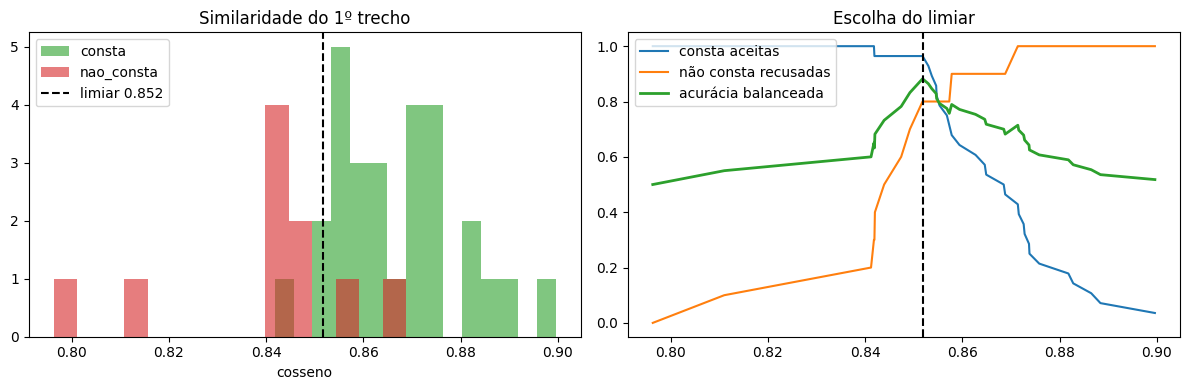

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for tipo, cor in [("consta", "tab:green"), ("nao_consta", "tab:red")]:
    ax[0].hist(df_busca[df_busca.tipo == tipo].score_top1, bins=15, alpha=0.6, label=tipo, color=cor)
ax[0].axvline(LIMIAR, color="k", ls="--", label=f"limiar {LIMIAR:.3f}")
ax[0].set_title("Similaridade do 1º trecho"); ax[0].set_xlabel("cosseno"); ax[0].legend()
ax[1].plot(curva.limiar, curva.consta_aceitas, label="consta aceitas")
ax[1].plot(curva.limiar, curva.nao_consta_recusadas, label="não consta recusadas")
ax[1].plot(curva.limiar, curva.balanceada, label="acurácia balanceada", lw=2)
ax[1].axvline(LIMIAR, color="k", ls="--"); ax[1].set_title("Escolha do limiar"); ax[1].legend()
plt.tight_layout(); plt.savefig("avaliacao/limiar.png", dpi=120); plt.show()

## 4 · Geração fundamentada

Modelo local **Qwen2.5-1.5B-Instruct** (roda na T4 do Colab). A saída é sempre um JSON validado com Pydantic:
`resposta`, `fonte`, `trecho_id`, `nao_consta`. Se o 1º trecho fica abaixo do limiar, a resposta é a recusa "Não consta na base".

Configurações comparadas:
- **A · sem contexto**: o mesmo modelo, só com a pergunta
- **B · RAG simples**: 3 trechos mais parecidos + limiar
- **C · RAG + LoRA**: igual à B, com o modelo especializado (seção 5)

In [10]:
from ia.gerador import Gerador, responder
from ia.avaliacao import pontuar
gerador = Gerador()
exemplo = responder(casos[0]["pergunta"], "B_rag_simples", gerador, buscador, LIMIAR)
print("Pergunta:", casos[0]["pergunta"])
print(json.dumps(exemplo["saida"], ensure_ascii=False, indent=1))
print("Trechos recuperados:", exemplo["recuperados"])

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Pergunta: Qual é a largura mínima da faixa livre da calçada em São Paulo?
{
 "resposta": "A largura mínima da faixa livre da calçada em São Paulo deve ser de 1,20m (um metro e vinte centímetros).",
 "fonte": "[D59671-art26-1]",
 "trecho_id": "D59671-art26-1",
 "nao_consta": false
}
Trechos recuperados: [(0.8828, 'D59671-art26-1'), (0.8782, 'D59671-art24-1'), (0.8738, 'D59671-art4-4')]


In [13]:
resultados = []
def rodar(config):
    for c in casos:
        r = responder(c["pergunta"], config, gerador, buscador, LIMIAR)
        resultados.append({"config": config, "id": c["id"], "tipo": c["tipo"], "pergunta": c["pergunta"],
                           "esperado": c["resposta_esperada"], "saida": json.dumps(r["saida"], ensure_ascii=False),
                           "bruto": r["bruto"], "recuperados": r["recuperados"], "tempo_s": r["tempo_s"],
                           "relevantes": sorted(relevantes(c, trechos)) if c["tipo"] == "consta" else [],
                           **pontuar(c, r)})
    print(config, "concluída")

rodar("A_sem_contexto")
rodar("B_rag_simples")

A_sem_contexto concluída
B_rag_simples concluída


## 5 · Especialização com LoRA

**Dados de treino sintéticos, sem usar as perguntas de teste:**
- *positivos*: o modelo-base lê um trecho e escreve uma pergunta de cidadão e a resposta curta; só fica o par cuja resposta está apoiada no trecho;
- *negativos*: perguntas fora do tema com trechos aleatórios da base, ensinando a recusar.

Treino LoRA (r=16, q/k/v/o) por 2 épocas. O adaptador fica salvo em `modelo/lora_calcada`.

In [18]:
from ia import lora
t0 = time.time()
pares = lora.gerar_pares(gerador, trechos, n=200)
exemplos = lora.montar_exemplos(pares, trechos, buscador)
print(f"Pares positivos aprovados: {len(pares)} | exemplos de treino (com negativos): {len(exemplos)} | {time.time()-t0:.0f}s")
with open("avaliacao/treino_lora.jsonl", "w", encoding="utf-8") as f:
    for e in exemplos: f.write(json.dumps(e, ensure_ascii=False) + "\n")
pd.DataFrame([{"pergunta": p["pergunta"], "resposta": p["resposta"], "trecho": p["trecho"]["id"]} for p in pares]).head(8)

Pares positivos aprovados: 176 | exemplos de treino (com negativos): 230 | 463s


,pergunta,resposta,trecho
0,Qual documento é necessário para realizar o fechamento de uma via pública em São Paulo?,Alvará de Alinhamento e Nivelamento,L15442-art4-1
1,Qual é a distância mínima entre os limites da calçada para permitir o acesso de veículos em uma esquina?,"O acesso de veículos em lote de esquina deverá distar, no mínimo, 6m (seis metros) do início do ponto de encontro do...",D59671-art5-2
2,Qual é a finalidade da Lei Brasileira de Inclusão?,Afinalidade é incentivar a fabricação de veículos acessíveis e promover sua utilização como táxis e vans para garant...,LBI-art50-1
3,O que é considerado uma forma de inclusão da pessoa com deficiência no trabalho?,"A colocação competitiva, em igualdade de oportunidades com as outras pessoas, seguindo as regras de acessibilidade, ...",LBI-art37-1
4,Qual é uma das principais responsabilidades do Estado brasileiro na área da educação?,"O Estado deve garantir a acessibilidade e inclusão educacional, oferecendo recursos como planos de atendimento educa...",LBI-art28-2
5,Qual é a penalidade para quem mantém mobiliário urbano ilegalmente por mais de 60 dias?,A Prefeitura pode efetuar a reparação ou remoção do mobiliário urbano.,L15442-art18-1
6,Qual é a finalidade do plano de medidas técnicas mencionado na lei?,Permitir o uso da linguagem de sinais ou outra subtitulação.,L10098-art19-1
7,Qual é a responsabilidade do município em relação à iluminação pública?,O sistema de iluminação pública das vias e logradouros deverá proporcionar luminosidade suficiente e adequada à clas...,D59671-art33-1


trainable params: 4,358,144 || all params: 1,548,072,448 || trainable%: 0.2815


Step,Training Loss
10,0.272412
20,0.119919
30,0.098603
40,0.056621
50,0.072675


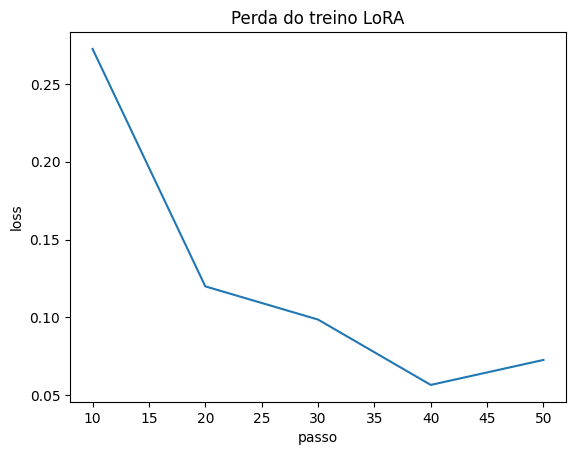

In [24]:
historico = lora.treinar(gerador, exemplos, "modelo/lora_calcada", epocas=2)
perdas = [(h["step"], h["loss"]) for h in historico if "loss" in h]
plt.plot(*zip(*perdas)); plt.title("Perda do treino LoRA"); plt.xlabel("passo"); plt.ylabel("loss")
plt.savefig("avaliacao/perda_lora.png", dpi=120); plt.show()

In [23]:
!sed -i 's/warmup_ratio=0.05,/warmup_steps=5,/' ia/lora.py
import importlib
from ia import lora
importlib.reload(lora)
gerador = Gerador()  # recarrega o modelo-base limpo
print("pronto")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

pronto


In [21]:
!pip uninstall -y -q torchao

In [25]:
rodar("C_rag_lora")

C_rag_lora concluída


## 6 · Placar das três configurações

In [26]:
from ia.avaliacao import placar
df = pd.DataFrame(resultados)
df.to_csv("avaliacao/resultados.csv", index=False)
tab = placar(df)
tab.to_csv("avaliacao/placar.csv")
tab

,acuracia_%,alucinacao_%,json_valido_%,recusa_correta_%,recusa_indevida_%,cita_fonte_certa_%,tempo_medio_s
config,,,,,,,
A_sem_contexto,0.0,68.4,55.3,0.0,3.6,3.6,2.2
B_rag_simples,52.6,31.6,89.5,100.0,7.1,71.4,2.2
C_rag_lora,52.6,39.5,97.4,100.0,7.1,75.0,3.9


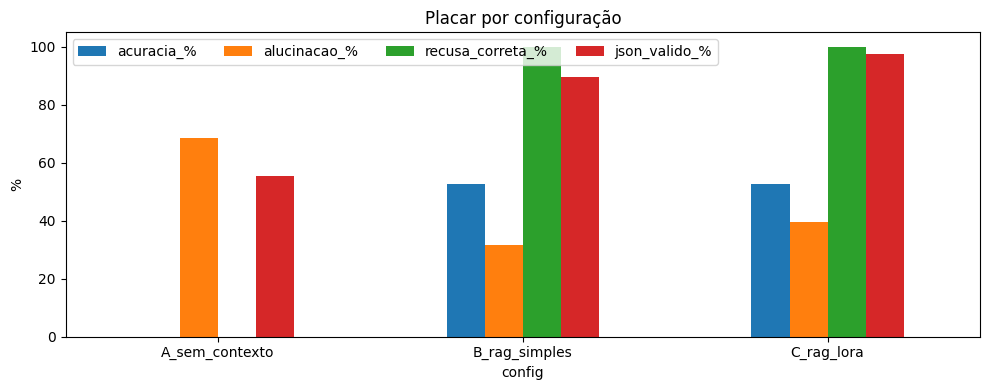

In [27]:
tab[["acuracia_%", "alucinacao_%", "recusa_correta_%", "json_valido_%"]].plot.bar(figsize=(10, 4), rot=0)
plt.title("Placar por configuração"); plt.ylabel("%"); plt.ylim(0, 105); plt.legend(loc="upper left", ncol=4)
plt.tight_layout(); plt.savefig("avaliacao/placar.png", dpi=120); plt.show()

**Interpretação** *(escrever depois de rodar, com os números do placar)*: compare A x B (efeito do contexto) e B x C (efeito do LoRA)
em acurácia, alucinação e recusa correta, e comente o custo em tempo.

## 7 · Erros reais

Todas as respostas erradas das configurações B e C, com o que foi recuperado. Escolha 5 para o relatório:
pergunta, resposta errada, causa (busca trouxe o trecho errado? modelo ignorou o trecho? formato inválido? recusa indevida?) e correção proposta.

In [28]:
erros = df[(df.config.isin(["B_rag_simples", "C_rag_lora"])) & (~df.correto)]
erros[["config", "id", "pergunta", "esperado", "saida", "recuperados", "relevantes"]]

,config,id,pergunta,esperado,saida,recuperados,relevantes
39,B_rag_simples,c02,Qual a inclinação transversal máxima permitida na faixa livre?,Não superior a 3%.,"{""resposta"": ""Não consta na base."", ""fonte"": null, ""trecho_id"": null, ""nao_consta"": true}","[(0.8418, D59671-art24-1), (0.835, D59671-art22-1), (0.8257, D59671-art4-3)]","[D59671-art22-1, D59671-art4-1, D59671-art4-3]"
40,B_rag_simples,c03,Qual a largura mínima da faixa de serviço da calçada?,70 cm.,"{""resposta"": ""A largura mínima da faixa de serviço da calçada é de 1,20m (um metro e vinte centímetros)."", ""fonte"": ...","[(0.8685, D59671-art4-4), (0.8678, D59671-art26-1), (0.8597, D59671-art24-1)]","[D59671-art10-1, D59671-art20-1, D59671-art22-1, D59671-art4-2]"
41,B_rag_simples,c04,Em que calçadas pode existir a faixa de acesso?,Somente em calçadas com mais de 2 m de largura.,"{""resposta"": ""A faixa de acesso pode existir nas calçadas e demais vias públicas, conforme o art. 31 do Decreto Muni...","[(0.8573, D59671-art10-1), (0.8498, D59671-art31-1), (0.849, D59671-art24-1)]","[D59671-art10-1, D59671-art12-1, D59671-art20-1, D59671-art22-1, D59671-art4-2, D59671-art4-3]"
43,B_rag_simples,c06,Posso rebaixar a guia da esquina para entrada de carro?,Não. É vedado o rebaixamento de guias nas esquinas para acesso de veículos.,"{""resposta"": ""Não"", ""fonte"": ""[D59671-art24-1]"", ""trecho_id"": ""Art. 24."", ""nao_consta"": false}","[(0.8758, D59671-art10-1), (0.8455, D59671-art8-1), (0.8431, D59671-art24-1)]","[D59671-art10-1, D59671-art2-2, D59671-art20-1, D59671-art21-1, D59671-art23-1, D59671-art40-1, D59671-art5-1, D5967..."
44,B_rag_simples,c07,O rebaixamento de guia para veículos pode ocupar quanto da testada do imóvel?,"No máximo 50% da testada, salvo residência unifamiliar e habitações agrupadas horizontalmente.",null,"[(0.8627, D59671-art10-1), (0.8405, L15442-art26-1), (0.8334, D59671-art8-1)]","[D59671-art10-1, D59671-art4-2]"
47,B_rag_simples,c10,"Em um lote de esquina, a que distância mínima da esquina pode ficar o acesso de veículos?",No mínimo 6 m do encontro dos alinhamentos.,"{""resposta"": ""A que distância mínima da esquina deve ficar o acesso de veículos em um lote de esquina?"", ""fonte"": ""[...","[(0.8594, D59671-art5-2), (0.8502, D59671-art10-1), (0.8446, D59671-art5-1)]",[]
48,B_rag_simples,c11,Uma árvore quebrou a calçada da minha casa. Sou obrigado a consertar?,"A obrigação fica suspensa até o corte ou a supressão da árvore; depois, há 30 dias para regularizar.",null,"[(0.8547, D59671-art32-1), (0.8441, D59671-art34-1), (0.8426, D59671-art13-1)]","[D59671-art32-1, L15442-art9-1]"
50,B_rag_simples,c13,Qual norma deve ser seguida na sinalização tátil de alerta e direcional da calçada?,"As normas técnicas da ABNT, com parâmetros definidos em portaria das Secretarias.","{""resposta"": ""A norma que deve ser seguida na sinalização tátil de alerta e direcional da calçada é a Lei nº 10.098/...","[(0.8818, LBI-art10-2), (0.8798, D59671-art11-1), (0.8773, L10098-art10-2)]","[D59671-art10-2, D59671-art11-1]"
51,B_rag_simples,c14,"Se a calçada for estreita, ela pode ter só duas faixas?","Sim, quando a largura for insuficiente admite-se a organização em duas faixas.","{""resposta"": ""Não"", ""fonte"": ""[D59671-art26-1]"", ""trecho_id"": ""D59671-art26-1"", ""nao_consta"": false}","[(0.853, D59671-art26-1), (0.8503, D59671-art24-1), (0.8494, D59671-art4-4)]","[D59671-art2-2, D59671-art4-3]"
54,B_rag_simples,c17,Qual o prazo para regularizar quando o problema é mobiliário urbano irregular na calçada?,20 dias.,"{""resposta"": ""A Prefeitura poderá efetuar a reparação e a remoção do mobiliário urbano, caso a irregularidade previs...","[(0.8865, D59671-art32-1), (0.8786, D59671-art35-1), (0.8713, L15442-art18-1)]","[L15442-art11-1, L15442-art2-1, L15442-art24-1, L15442-art8-1]"


In [29]:
# 8 · Salvar e baixar os resultados para subir no GitHub
!zip -qr /content/resultados_ia.zip base/trechos.jsonl base/tabela_base.csv base/embeddings.npy base/fontes avaliacao modelo/lora_calcada
from google.colab import files
files.download("/content/resultados_ia.zip")
print("Depois: Arquivo → Baixar → Baixar o .ipynb (o notebook com as saídas) e suba em notebooks/")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Depois: Arquivo → Baixar → Baixar o .ipynb (o notebook com as saídas) e suba em notebooks/
